---
title: Exploratory Data Analysis
----

## Dataset Overview
- 3662 retina images taken using fundus photography (rear of the eye)
- Dataframe of clinician-rated severity levels, ranging from 0 to 4 (0 = no DR, 4 = Proliferative DR)
- Noise in both images (exposure differences, artifacts) and labels (inconsistency in diagnoses)

In [75]:
import pandas as pd
import numpy as np
import os
from PIL import Image, ImageEnhance, ImageOps
import cv2
from skimage import exposure
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

## Labels

Let's first take a look at our labels:

In [76]:
import pandas as pd

labels = pd.read_csv('../data/labels.csv')
labels.describe()

,diagnosis
count,3662.000000
mean,1.126980
std,1.298409
min,0.000000
25%,0.000000
50%,1.000000
75%,2.000000
max,4.000000


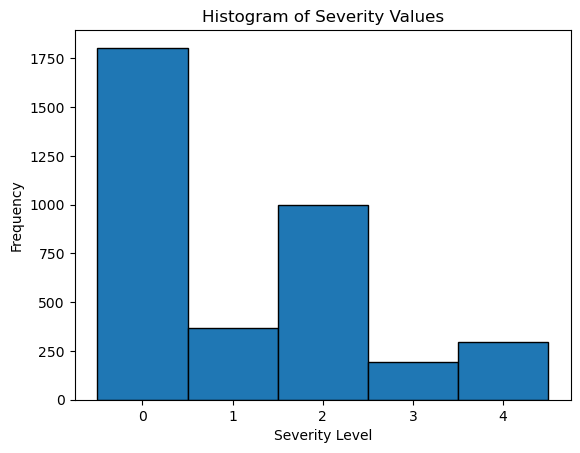

In [77]:
# Plot a histogram of the labels

plt.hist(labels['diagnosis'], bins=range(6), edgecolor='black', align='left')
plt.xlabel('Severity Level')
plt.ylabel('Frequency')
plt.title('Histogram of Severity Values')
plt.xticks(range(5))
plt.show()

The class imbalance in this dataset is important to note. Given that almost half of all images were given no DR diagnosis, some models may develop a bias towards less severe ratings, which should be prevented.

## Diagnosing Diabetic Retinopathy

Given a retina image, what characteristics do doctors look for to inform their diagnosis?

![](../data/dr_example.jpg)

*Figure 1: Diabetic Retinopathy Diagram. Source: [Lions Eye Institute](https://www.lei.org.au/services/eye-health-information/diabetic-retinopathy/)*

As you will see in the images below, the most visible signs of DR include hard exudates (bright white/yellow spots) and hemorrhages. Abnormal blood vessel growth is evident in some cases but is harder to detect. In general, a healthy retina appears much more clear, with well-defined retinal veins and consistent coloring.

## Image Dataset

Let's look at a few retina images for each possible label:

In [78]:
def load_images(path):
    images = []
    all_filenames = sorted([f for f in os.listdir(path)])
    
    for filename in all_filenames:
        img_path = os.path.join(path, filename)
        img = Image.open(img_path).convert('RGB')
        images.append(img)

    image_filenames = [filename.split('.')[0] for filename in all_filenames]
    return image_filenames, images

In [79]:
image_path = "../data/sampled_images"
image_filenames, images = load_images(image_path)

In [ ]:
def show_images(images, labels_df=labels, image_filenames=image_filenames, samples_per_class=5):
    fig, axes = plt.subplots(5, samples_per_class, figsize=(samples_per_class * 3, 15))
    fig.suptitle("Retinal Images by Severity Level", fontsize=16)
    available_images = set(image_filenames)
    
    for label in range(5):  # For each diagnosis level 0-4
        # Filter labels to only include images in our sampled dataset
        available_for_label = labels_df[
            (labels_df['diagnosis'] == label) & 
            (labels_df['id_code'].isin(available_images))
        ]['id_code'].iloc[:samples_per_class]
        
        for i, id_code in enumerate(available_for_label):
            if i >= samples_per_class:
                break
                
            # Find the corresponding image index
            img_idx = image_filenames.index(id_code)
            ax = axes[label, i]
            ax.imshow(images[img_idx])
            ax.axis('off')
            ax.set_title(f'Severity {label}')
        
        # Fill remaining slots with empty plots if not enough images
        for i in range(len(available_for_label), samples_per_class):
            ax = axes[label, i]
            ax.text(0.5, 0.5, 'No More\nImages', ha='center', va='center', transform=ax.transAxes)
            ax.axis('off')
            ax.set_title(f'Severity {label}')
    
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

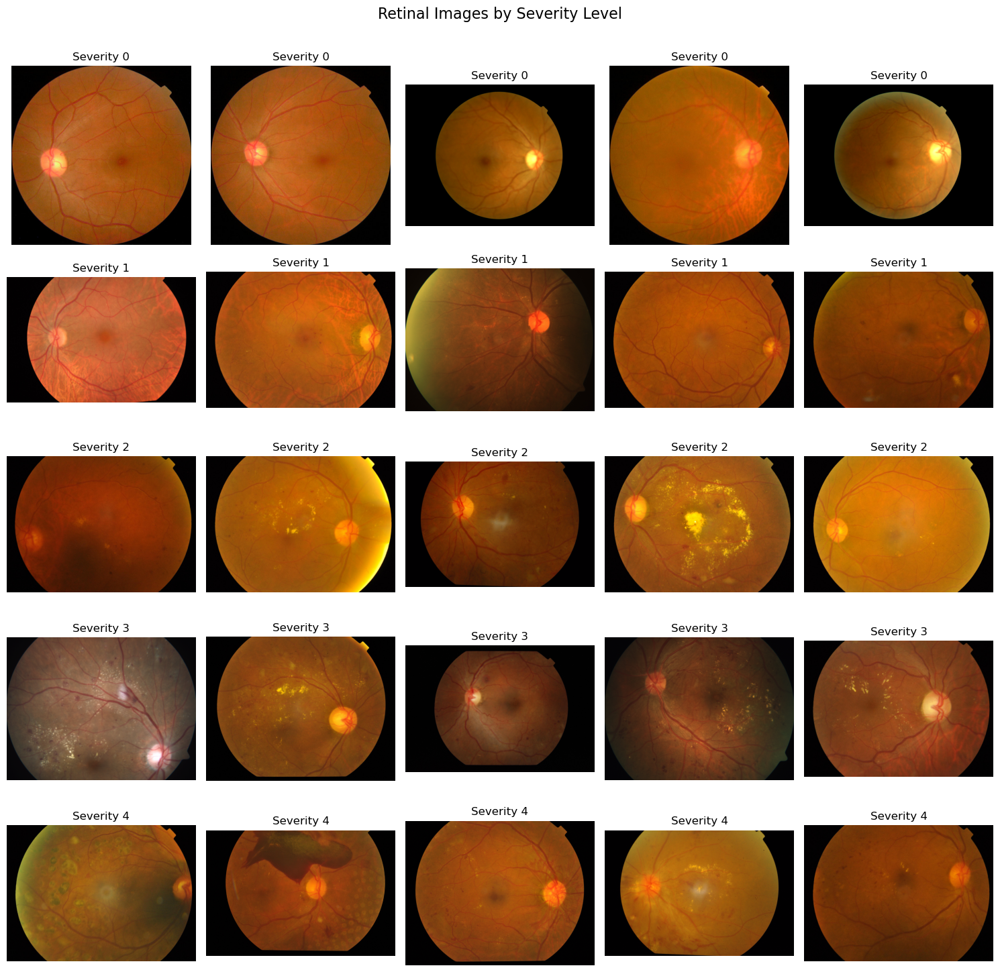

In [81]:
show_images(images)

Much like the diagram, white/yellow hard exudates appear consistently with more severe cases of DR. However, most symptoms are difficult to see due to varying exposure and focus. To ensure our model can detect these characteristics, it could be beneficial to apply image enhancing techniques. Additionally, these images vary in size and border width. Some images capture the entire eye, while others crop out the top and/or sides.

## Preprocessing

There are a few ways we can preprocess these images to be better suited to deep learning models. We will perform 3 changes:
- **Cropping:** The large black borders in some of the images will make it harder for the model to identify where the important features are.
- **Resizing:** Machine learning models typically require consistent input dimensions.
- **Enhancement:** Overexposure or underexposure can make DR symptoms less visible, so highlighting these could improve model accuracy.

### 1. Cropping

To reduce noise and maximize the region of interest, we will crop images by removing rows and columns of pixels that consist solely of dark pixels. "Dark", in this function, is defined as any pixel in a grayscale image with a brightness value less than or equal to 5.

In [82]:
def convert_to_numpy(images):
    return [np.array(img) for img in images]

In [ ]:
def crop_images(images, tol=5):
    cropped_images = []
    for img in images:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) # Convert to grayscale
        mask = gray > tol
    
        if not mask.any():
            return img
    
        rows = mask.any(1) # Which rows have any non-dark pixels?
        cols = mask.any(0) # Which columns have any non-dark pixels?
    
        cropped_images.append(img[np.ix_(rows, cols)])
        
    return cropped_images

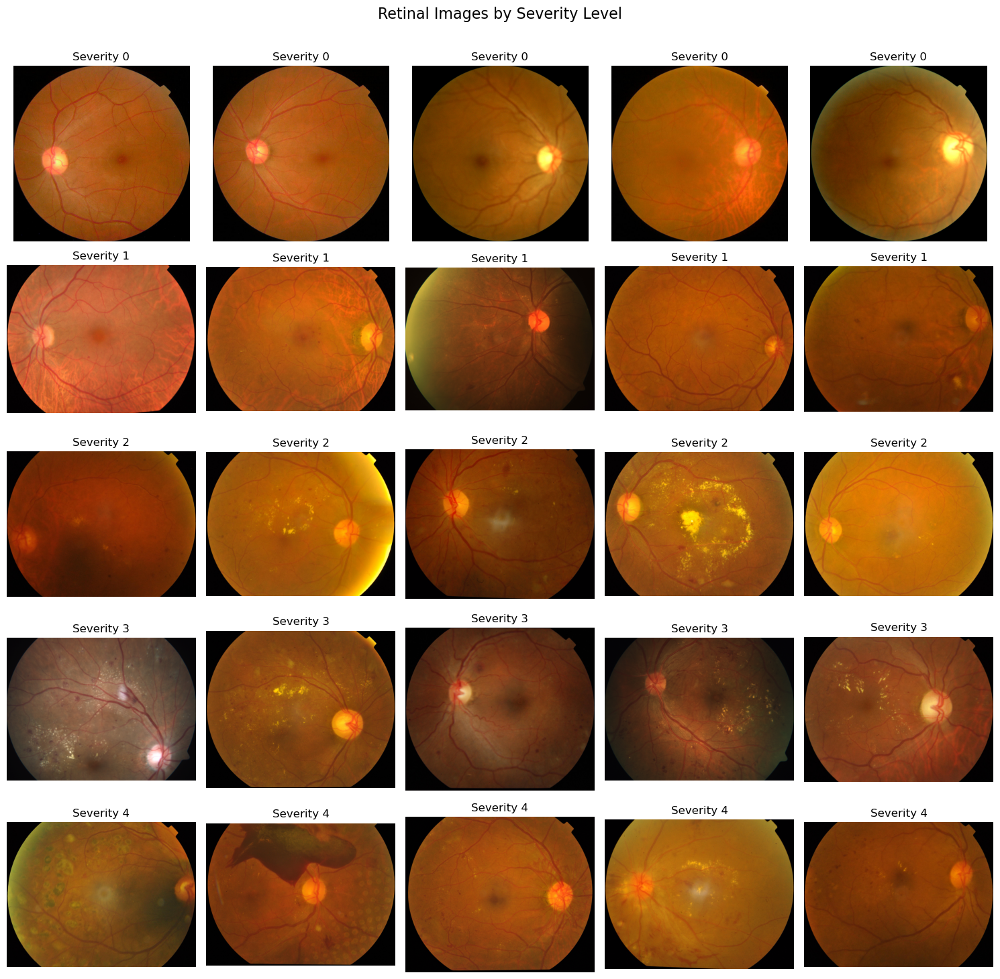

In [ ]:
np_images = convert_to_numpy(images)
cropped_images = crop_images(np_images)
show_images(cropped_images)

We now have a maximized view of the retina.

### 2. Resizing

Next, we need to resize the images to a target image size, which will be (224, 224). This is a standard in deep learning as the ImageNet dataset, which was used to train the most popular CNN models, consisted of (224, 224, 3) images. Many pretrained CNN architectures will require it.

In [87]:
def resize(cropped_images, target_size=(224, 224)):
    resized_images = []

    for img in cropped_images:
        resized = cv2.resize(img, target_size)
        resized_images.append(resized)
        
    return resized_images

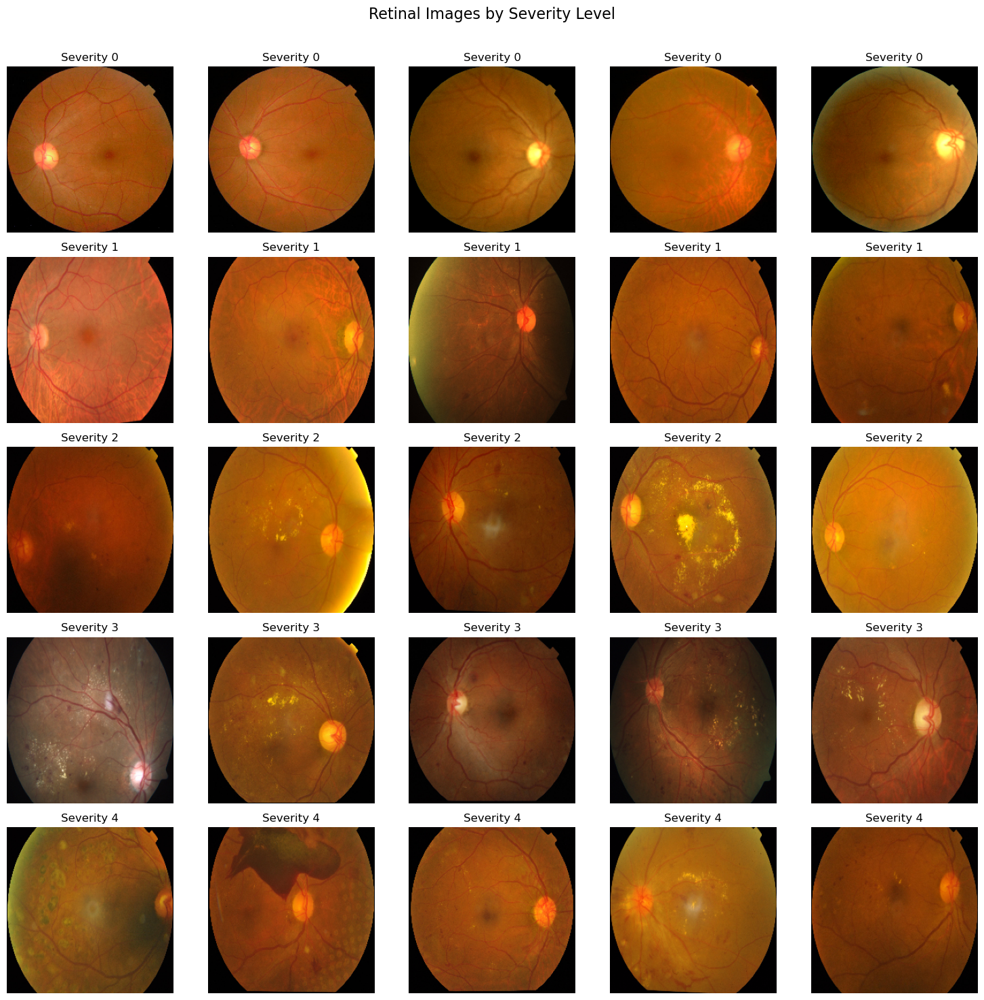

In [88]:
resized_images = resize(cropped_images)
show_images(resized_images)

Our images are now properly standardized! Although the shapes are a bit distorted in some images, their sizes match and maximize the signal in the retina. Another option would be to apply a resizing function with padding to preserve the aspect ratio, but we will prioritize minimizing the black borders as deep learning models are mostly invariant to minor distortions.

### 3. Image Enhancement

To enhance distinctive features, we will apply a processing technique by Ben Graham, referenced in [**this**](https://www.kaggle.com/code/ratthachat/aptos-eye-preprocessing-in-diabetic-retinopathy#Appendix-B.-Inconsistency-of-Ophthalmologist's-Estimation) notebook.

The function below applies an unsharp masking to enhance image details and constrast. This involves creating a blurred version of the image and subtracting it from the original. Both versions are given weights to control enhancement.

Parameters:
- **orig_weight:** Controls how much of the original image to add
- **blur_weight:** Controls how much of the blurred image to subtract (must be negative)
- **gb_sigma:** Controls the strength and spread of the blurring effect
- **gamma:** Constant added for brightness offset

Formula (with our set values):
-  Enhanced Pixel Values = 4xOriginal - 4xBlurred + 128

In [ ]:
def enhance_images(images, orig_weight=4, blur_weight=-4, gb_sigma=10, gamma=128):
    enhanced_images = []
    for image in images:
        image=cv2.addWeighted(image, orig_weight, cv2.GaussianBlur(image, (0,0) , gb_sigma) , blur_weight, gamma)
        enhanced_images.append(image)
    return enhanced_images

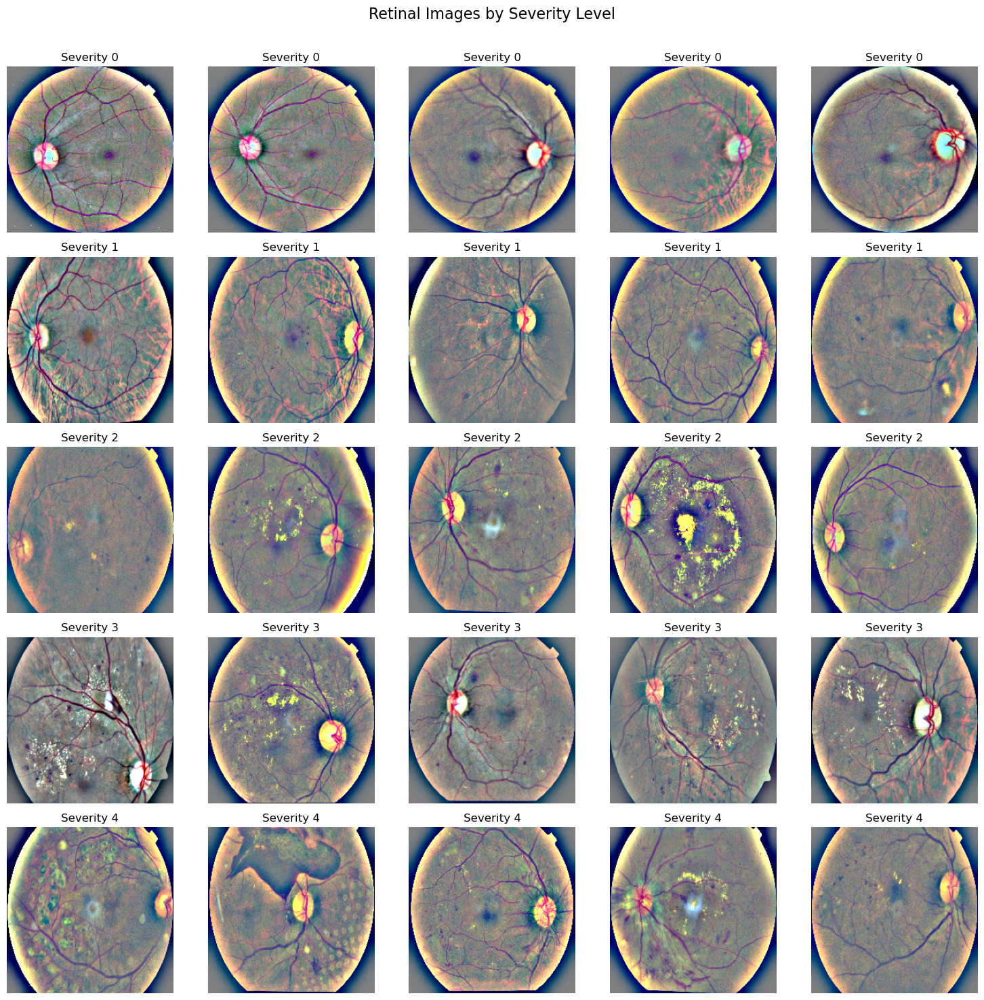

In [92]:
enhanced_images = enhance_images(resized_images)
show_images(enhanced_images)

With image enhancement, we can see:
- Blood vessels become more prominent
- Constrast between different retinal features increases
- Overall sharpness improves for better feature detection

Now that our images are cropped, resized, and enhanced, we can begin the modeling process. 